# Dora Maar — Artnet Image Scraper

Scrapes all Dora Maar artworks from Artnet using a visible Firefox browser, downloads every thumbnail image, and saves a metadata CSV with file paths.

In [1]:
import os, ssl, certifi
os.environ["SSL_CERT_FILE"]      = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
ssl._create_default_https_context = ssl.create_default_context

import re
import time
import pandas as pd
import browser_cookie3
from pathlib import Path
from bs4 import BeautifulSoup
from curl_cffi import requests as curl_requests

IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

print("Setup complete. Images will be saved to:", IMAGES_DIR.resolve())

Setup complete. Images will be saved to: /Users/pietro/Desktop/Maar/images


---
## Step 1 — Fetch all 64 Artnet pages

**Before running this cell:**  
1. Open Firefox manually and go to `https://www.artnet.com/artists/dora-maar/`  
2. Solve any CAPTCHA until artworks are visible  
3. Come back here and run the cell — cookies are read directly from your Firefox profile

In [ ]:
TOTAL_PAGES = 64
BASE_URL    = "https://www.artnet.com/artists/dora-maar/{}"

# --- Read cookies straight from your Firefox profile (no Selenium needed) ---
ff_cookies = browser_cookie3.firefox(domain_name=".artnet.com")
cookie_list = list(ff_cookies)
print(f"Read {len(cookie_list)} artnet.com cookies from Firefox profile:\n")
for c in cookie_list:
    print(f"  {c.name:40s}  {c.value[:60]}")

incapsula = [c for c in cookie_list if "incap" in c.name.lower() or "visid" in c.name.lower()]
print(f"\nIncapsula cookies found: {len(incapsula)}")
for c in incapsula:
    print(f"  {c.name} = {c.value[:80]}")

if not incapsula:
    print("\n⚠  No Incapsula cookies found.")
    print("   Make sure you opened artnet.com in Firefox and solved any CAPTCHA before running this cell.")

# --- curl_cffi session: Firefox TLS fingerprint + your real browser cookies ---
session = curl_requests.Session(impersonate="firefox135")
for c in cookie_list:
    session.cookies.set(c.name, c.value, domain=c.domain)

print(f"\nSession ready. Fetching {TOTAL_PAGES} pages...\n")

# --- Fetch all 64 pages ---
html_pages = {}

for page in range(1, TOTAL_PAGES + 1):
    url = BASE_URL.format(page)
    try:
        resp = session.get(url, timeout=15)
        size = len(resp.text)
        blocked = "Incapsula" in resp.text or size < 5_000
        status = "BLOCKED ⚠" if blocked else "ok"
        print(f"  Page {page:2d}/{TOTAL_PAGES}  {resp.status_code}  {size:>8,} chars  [{status}]")
        html_pages[page] = "" if blocked else resp.text
    except Exception as e:
        print(f"  Page {page:2d}/{TOTAL_PAGES}  ERROR: {e}")
        html_pages[page] = ""
    if page < TOTAL_PAGES:
        time.sleep(5)

ok = sum(1 for h in html_pages.values() if h)
print(f"\nDone. {ok}/{TOTAL_PAGES} pages fetched successfully.")


In [ ]:
from artnet_html_parser import save_pages
# --- Save HTML to disk so Step 2 can be re-run without re-fetching ---
save_pages(html_pages, "artnet_html")

---
## Step 2 — Parse artworks & save catalog CSV

Loads HTML from `artnet_html/`, parses every artwork block, and saves `artnet_catalog_raw.csv`.  
Columns: `page, title, year, gallery_name, gallery_url, price, img_url, detail_url`

In [ ]:
html_pages[1]

In [ ]:
from artnet_html_parser import parse_pages, load_pages

CATALOG_RAW = Path("artnet_catalog_raw.csv")

html_pages = load_pages("artnet_html")
print(f"Loaded {len(html_pages)} HTML files from artnet_html/")

df = parse_pages(html_pages)
print(f"Parsed {len(df)} unique artworks")

df.to_csv(CATALOG_RAW, index=False)
print(f"Saved to {CATALOG_RAW.resolve()}")
df.head(10)

---
## Step 3 — Download images & save metadata CSV

Images saved to `images/` as `{index:04d}_{slug}.jpg`.  
Progress is written to `artnet_catalog.csv` every 50 downloads so the run can be resumed.

In [ ]:
CSV_PATH = Path("artnet_catalog.csv")

# Resume from existing CSV if present
if CSV_PATH.exists():
    df_done = pd.read_csv(CSV_PATH)
    done_urls = set(df_done["img_url"])
    print(f"Resuming — {len(df_done)} already downloaded.")
else:
    df_done = pd.DataFrame()
    done_urls = set()

records = []
img_session = curl_requests.Session(impersonate="firefox135")

for idx, row in df.iterrows():
    if row["img_url"] in done_urls:
        continue

    slug = re.sub(r"[^a-z0-9]+", "-", row["img_url"].split("/")[-1].lower())[:80]
    filename = f"{idx:04d}_{slug}"
    if not filename.endswith(".jpg"):
        filename += ".jpg"
    local_path = IMAGES_DIR / filename

    try:
        resp = img_session.get(row["img_url"], timeout=15)
        resp.raise_for_status()
        local_path.write_bytes(resp.content)
        status = "ok"
    except Exception as e:
        local_path = Path("")
        status = f"error: {e}"

    records.append({
        **row.to_dict(),
        "local_path": str(local_path),
        "status":     status,
    })

    if len(records) % 50 == 0:
        batch = pd.concat([df_done, pd.DataFrame(records)], ignore_index=True)
        batch.to_csv(CSV_PATH, index=False)
        print(f"  Checkpoint: {len(batch)} rows saved.")

    time.sleep(0.15)

df_catalog = pd.concat([df_done, pd.DataFrame(records)], ignore_index=True)
df_catalog.to_csv(CSV_PATH, index=False)

ok = (df_catalog["status"] == "ok").sum()
print(f"\nDone. {ok} / {len(df_catalog)} images downloaded.")
print(f"Catalog saved to: {CSV_PATH.resolve()}")
df_catalog.head(10)

---
## Step 4 — Scrape Picasso's Dora Maar artworks

Fetches the 62 artworks from `pablo-ruiz-picasso.net/theme-doramaar.php`, visits each detail page for clean title + year, downloads images to `images/picasso_dora/`, and saves `picasso_dora_catalog.csv`.

In [ ]:
import importlib, parse_html
importlib.reload(parse_html)
from parse_html import scrape_picasso_dora_maar

PICASSO_DIR = Path("images/picasso_dora")
PICASSO_DIR.mkdir(parents=True, exist_ok=True)
PICASSO_CSV = Path("picasso_dora_catalog.csv")

# --- Scrape listing + visit each detail page ---
pic_session = curl_requests.Session(impersonate="firefox135")
records = scrape_picasso_dora_maar(session=pic_session)
print(f"Scraped {len(records)} artworks from pablo-ruiz-picasso.net")

# --- Download full-size images ---
for i, rec in enumerate(records):
    slug       = re.sub(r"[^a-z0-9]+", "-", rec["img_url"].split("/")[-1].lower())[:60]
    local_path = PICASSO_DIR / f"{i:03d}_{slug}"
    if not local_path.suffix:
        local_path = local_path.with_suffix(".jpg")

    try:
        r = pic_session.get(rec["img_url"], timeout=15)
        r.raise_for_status()
        local_path.write_bytes(r.content)
        rec["local_path"] = str(local_path)
        rec["dl_status"]  = "ok"
    except Exception as e:
        rec["local_path"] = ""
        rec["dl_status"]  = f"error: {e}"

    if (i + 1) % 10 == 0:
        print(f"  downloaded {i+1}/{len(records)}…")

df_picasso = pd.DataFrame(records)
df_picasso.to_csv(PICASSO_CSV, index=False)

ok = (df_picasso["dl_status"] == "ok").sum()
print(f"\nDone. {ok}/{len(df_picasso)} images saved to {PICASSO_DIR}")
print(f"Catalog saved to: {PICASSO_CSV.resolve()}")
df_picasso.head(10)

---
## Step 5 — Scrape & download top Google Images results for "dora maar"

Fetches the first results page from `google.com/search?tbm=isch`, extracts ~90–100 image URLs using `parse_html.parse_google_images_html`, downloads each to `images/google_search/`, and saves `google_search_results.csv`.

**Run with Firefox open** (uses your Google cookies to avoid CAPTCHAs).

In [ ]:
import json, random
from urllib.parse import quote_plus
from parse_html import parse_google_images_html

GOOG_DIR = Path("images/google_search")
GOOG_DIR.mkdir(parents=True, exist_ok=True)
GOOG_CSV = Path("google_search_results.csv")

QUERY = "dora maar"

# --- Firefox cookies for Google session ---
goog_cookies = browser_cookie3.firefox(domain_name=".google.com")
goog_session = curl_requests.Session(impersonate="firefox135")
for c in goog_cookies:
    goog_session.cookies.set(c.name, c.value, domain=c.domain)

# --- Fetch the full Google Images results page ---
url  = f"https://www.google.com/search?q={quote_plus(QUERY)}&tbm=isch&hl=en"
resp = goog_session.get(url, timeout=20)
ranked = parse_google_images_html(resp.text)
print(f"status={resp.status_code}  html={len(resp.text):,} chars  images={len(ranked)}")

if not ranked:
    raise SystemExit("Step 4 aborted — no images extracted.")

# --- Resume from existing CSV (guard against empty file) ---
if GOOG_CSV.exists() and GOOG_CSV.stat().st_size > 0:
    df_goog_done = pd.read_csv(GOOG_CSV)
    done_urls    = set(df_goog_done["img_url"])
    print(f"Resuming — {len(df_goog_done)} already in CSV.")
else:
    df_goog_done = pd.DataFrame(columns=[
        "rank", "title", "source_domain", "source_url",
        "img_url", "thumbnail_url", "local_path", "dl_status", "lens_count",
    ])
    done_urls = set()

dl_session  = curl_requests.Session(impersonate="firefox135")
new_records = []

for rank, item in enumerate(ranked):
    if item["img_url"] in done_urls:
        continue

    ext        = re.search(r'\.(jpe?g|png|gif|webp)', item["img_url"], re.IGNORECASE)
    ext        = ("." + ext.group(1).lower()) if ext else ".jpg"
    slug       = re.sub(r"[^a-z0-9]+", "-", item["img_url"].split("/")[-1].lower())[:60]
    local_path = GOOG_DIR / f"{rank:04d}_{slug}{ext}"

    try:
        r = dl_session.get(item["img_url"], timeout=15)
        r.raise_for_status()
        local_path.write_bytes(r.content)
        dl_status = "ok"
    except Exception as e:
        local_path = Path("")
        dl_status  = f"error: {e}"

    new_records.append({
        "rank":          rank,
        "title":         item["title"],
        "source_domain": item["source_domain"],
        "source_url":    item["source_url"],
        "img_url":       item["img_url"],
        "thumbnail_url": item["thumbnail_url"],
        "local_path":    str(local_path),
        "dl_status":     dl_status,
        "lens_count":    "",
    })

    if len(new_records) % 50 == 0:
        batch = pd.concat([df_goog_done, pd.DataFrame(new_records)], ignore_index=True)
        batch.to_csv(GOOG_CSV, index=False)
        print(f"  Checkpoint: {len(batch)} rows saved.")

    time.sleep(random.uniform(0.3, 0.8))

df_goog = pd.concat([df_goog_done, pd.DataFrame(new_records)], ignore_index=True)
df_goog.to_csv(GOOG_CSV, index=False)

ok = (df_goog["dl_status"] == "ok").sum()
print(f"\nDone. {ok}/{len(df_goog)} images downloaded to {GOOG_DIR}")
print(f"Catalog saved to: {GOOG_CSV.resolve()}")
df_goog.head(10)

---
## Step 5b — Cross-catalog deduplication

Hashes all images from all three catalogs using perceptual hashing (`imagehash.phash`), flags near-identical pairs (Hamming distance ≤ 8) as `is_dup=True`, and writes the flag back to each catalog's CSV. Shows a preview of flagged pairs so you can sanity-check the results.

In [ ]:
import imagehash
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

HASH_THRESHOLD = 8   # Hamming bits — 0=identical, 64=completely different

CATALOGS = [
    {"csv": Path("google_search_results.csv"), "status_col": "dl_status", "label": "google"},
    {"csv": Path("picasso_dora_catalog.csv"),   "status_col": "dl_status", "label": "picasso"},
    {"csv": Path("artnet_catalog.csv"),         "status_col": "status",    "label": "artnet"},
]

# ── Build unified entry list across all catalogs ──────────────────────────────
all_entries = []
dfs = {}
for cat in CATALOGS:
    if not Path(cat["csv"]).exists():
        print(f"Skipping {cat['csv']} (not found)")
        continue
    df = pd.read_csv(cat["csv"])
    dfs[cat["label"]] = (df, cat["csv"])
    ok = df[df[cat["status_col"]].eq("ok")]
    for df_idx, row in ok.iterrows():
        path = str(row.get("local_path", ""))
        if path and Path(path).exists():
            all_entries.append({"catalog": cat["label"], "df_idx": df_idx, "local_path": path})

print(f"Hashing {len(all_entries)} images across all catalogs…")
hashes = {}
for pos, entry in enumerate(all_entries):
    try:
        hashes[pos] = imagehash.phash(Image.open(entry["local_path"]))
    except Exception:
        pass
    if (pos + 1) % 300 == 0:
        print(f"  {pos+1}/{len(all_entries)} hashed…")
print(f"  {len(hashes)}/{len(all_entries)} hashed successfully")

# ── O(n²) pairwise dedup — flag second and later occurrences ─────────────────
is_dup    = {}   # pos -> True
dup_pairs = []   # (keeper_pos, dup_pos) for preview

positions = list(hashes.keys())
for i, pos_i in enumerate(positions):
    if is_dup.get(pos_i):
        continue
    for pos_j in positions[i + 1:]:
        if not is_dup.get(pos_j) and hashes[pos_i] - hashes[pos_j] <= HASH_THRESHOLD:
            is_dup[pos_j] = True
            dup_pairs.append((pos_i, pos_j))

n_dup = sum(is_dup.values())
print(f"\nTotal duplicates flagged: {n_dup}  |  unique kept: {len(all_entries) - n_dup}")

# ── Write is_dup flag back to each catalog's CSV ─────────────────────────────
for label, (df, csv_path) in dfs.items():
    flagged = {all_entries[pos]["df_idx"] for pos in is_dup if all_entries[pos]["catalog"] == label}
    df["is_dup"] = df.index.map(lambda i: i in flagged)
    df.to_csv(csv_path, index=False)
    print(f"  {label}: {len(flagged)} dupes flagged → {Path(csv_path).name}")

# ── Preview duplicate pairs ───────────────────────────────────────────────────
n_show = min(30, len(dup_pairs))
if not dup_pairs:
    print("\nNo duplicates found.")
else:
    print(f"\nShowing {n_show} of {len(dup_pairs)} duplicate pairs:")
    fig, axes = plt.subplots(n_show, 2, figsize=(6, n_show * 2.4))
    if n_show == 1:
        axes = [axes]

    for ax_row, (keeper, dup) in zip(axes, dup_pairs[:n_show]):
        dist = hashes[keeper] - hashes[dup]
        for ax, pos, tag in [(ax_row[0], keeper, "KEEP"), (ax_row[1], dup, "DUP")]:
            entry = all_entries[pos]
            try:
                img = Image.open(entry["local_path"]).convert("RGB")
                img.thumbnail((300, 300))
                ax.imshow(img)
            except Exception:
                ax.text(0.5, 0.5, "load error", ha="center", va="center",
                        transform=ax.transAxes, fontsize=8)
            ax.set_title(f"{tag}  [{entry['catalog']}]  dist={dist}", fontsize=7)
            ax.axis("off")

    plt.suptitle(
        f"Cross-catalog duplicates — {n_show} of {len(dup_pairs)} pairs  (threshold={HASH_THRESHOLD})",
        fontsize=10, y=1.002,
    )
    plt.tight_layout()
    plt.savefig("dedup_preview.png", dpi=100, bbox_inches="tight")
    plt.show()
    print(f"Preview saved to dedup_preview.png")


In [4]:
## DEBUG
#  import json
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# from PIL import Image
# from pathlib import Path

# # ── Pairs from manual inspection (indices into artnet_catalog.csv) ────────────
# PAIRS = [
#     (943, 1232, 20), (943, 1473, 18), (943,  125, 12), (943, 1467, 32),
#     (943, 1356, 28), (943, 1428, 32), (943, 1431, 30), (943,  502, 32),
#     (1232, 1473, 16), (1232,  125, 20), (1232, 1467, 34), (1232, 1356, 32),
#     (1232, 1428, 30), (1232, 1431, 34), (1232,  502, 32),
#     (1473,  125, 14), (1473, 1467, 30), (1473, 1356, 32), (1473, 1428, 26),
#     (1473, 1431, 26), (1473,  502, 28),
#     (125,  1467, 32), (125,  1356, 28), (125,  1428, 26), (125,  1431, 30),
#     (125,   502, 30),
#     (1467, 1356, 32), (1467, 1428, 30), (1467, 1431, 36), (1467,  502, 32),
#     (1356, 1428, 26), (1356, 1431, 26), (1356,  502, 34),
#     (1428, 1431, 34), (1428,  502, 36),
#     (1431,  502, 30),
# ]
# PAIRS.sort(key=lambda p: p[2])   # sort by distance ascending

# # ── Load artnet ───────────────────────────────────────────────────────────────
# df = pd.read_csv("artnet_catalog.csv")
# df["vision_score_num"] = pd.to_numeric(df.get("vision_score"), errors="coerce").fillna(0)

# def meta_label(idx):
#     row   = df.loc[idx]
#     title = str(row.get("title", ""))[:38]
#     year  = str(row.get("year", "")).strip()
#     score = int(row.get("vision_score_num", 0))
#     full = partial = pages = 0
#     vd = row.get("vision_data", "")
#     if vd and str(vd) not in ("nan", "", "-2"):
#         try:
#             d = json.loads(vd)
#             full, partial, pages = d["full_matching_images"], d["partial_matching_images"], d["pages_with_matching_images"]
#         except Exception:
#             pass
#     is_dup = bool(row.get("is_dup", False))
#     parts = [f"idx={idx}", title]
#     if year and year != "nan":
#         parts.append(year)
#     parts.append(f"score={score}  full={full}  partial={partial}  pages={pages}")
#     if is_dup:
#         parts.append("★ is_dup=True")
#     return "\n".join(parts)

# # ── Render ────────────────────────────────────────────────────────────────────
# THUMB = 220
# n     = len(PAIRS)
# fig, axes = plt.subplots(n, 2, figsize=(10, n * 3.0), squeeze=False)

# for row_i, (idx_a, idx_b, dist) in enumerate(PAIRS):
#     color = "#d32f2f" if dist <= 8 else ("#ff9800" if dist <= 16 else "#9e9e9e")

#     for col_i, idx in enumerate([idx_a, idx_b]):
#         ax = axes[row_i][col_i]
#         ax.axis("off")
#         row = df.loc[idx]
#         try:
#             img = Image.open(str(row["local_path"])).convert("RGB")
#             img.thumbnail((THUMB, THUMB))
#             ax.imshow(img)
#         except Exception:
#             ax.text(0.5, 0.5, "load error", ha="center", va="center",
#                     transform=ax.transAxes, fontsize=8)
#         ax.set_title(meta_label(idx), fontsize=6.5, loc="left", pad=3)
#         for spine in ax.spines.values():
#             spine.set_visible(True)
#             spine.set_edgecolor(color)
#             spine.set_linewidth(2.5)

#     axes[row_i][0].text(
#         1.02, 0.5, f"dist={dist}",
#         transform=axes[row_i][0].transAxes,
#         ha="left", va="center", fontsize=9, fontweight="bold", color=color,
#     )

# legend_handles = [
#     mpatches.Patch(color="#d32f2f", label="dist ≤ 8  (phash threshold)"),
#     mpatches.Patch(color="#ff9800", label="dist 9–16"),
#     mpatches.Patch(color="#9e9e9e", label="dist > 16"),
# ]
# fig.legend(handles=legend_handles, loc="upper right", fontsize=8)
# plt.suptitle(f"Guernica — all {n} pairwise comparisons, sorted by Hamming distance",
#              fontsize=11, y=1.001)
# plt.tight_layout()
# plt.savefig("guernica_pairs_preview.png", dpi=100, bbox_inches="tight")
# plt.show()
# print(f"Saved guernica_pairs_preview.png")


---
## Step 6 — Google Lens exact-match count per image

For each downloaded image across all catalogs, uploads it to Google Lens and records the **exact matches** count (`udm=48`). Saves results back into each catalog's CSV. Rate-limited to ~10 s between requests; checkpoints every 10 images so the run is resumable.

In [ ]:
import os, ssl, certifi
os.environ["SSL_CERT_FILE"]      = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
ssl._create_default_https_context = ssl.create_default_context

import importlib, time, random, json
import pandas as pd
import parse_html
from pathlib import Path

importlib.reload(parse_html)
from parse_html import lens_exact_match_count, vision_web_count

# ── Choose scoring method ─────────────────────────────────────────────────────
METHOD = "vision"   # "lens"   → Google Lens scraping  → stores in lens_count
                    # "vision" → Cloud Vision API       → stores in vision_data + vision_score
# ─────────────────────────────────────────────────────────────────────────────

if METHOD == "lens":
    import browser_cookie3
    from curl_cffi import requests as curl_requests
    _session = curl_requests.Session(impersonate="firefox135")
    for c in browser_cookie3.firefox(domain_name=".google.com"):
        _session.cookies.set(c.name, c.value, domain=c.domain)
    col = "lens_count"
    def _score(path): return lens_exact_match_count(path, _session)
    def _store(df, idx, result):
        df.at[idx, "lens_count"] = result
    def _already_done(df):
        return pd.to_numeric(df["lens_count"], errors="coerce").ge(0).sum()
    def _not_scored(df):
        return df["lens_count"].isna() | df["lens_count"].eq("")
    def _sleep(): time.sleep(random.uniform(3, 8))
else:
    from google.cloud import vision as gv
    CREDENTIALS = Path("dora-494219-4123fdf73562.json")
    os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = str(CREDENTIALS)
    _vision_client = gv.ImageAnnotatorClient()
    col = "vision_data"
    def _score(path): return vision_web_count(path, CREDENTIALS, client=_vision_client)
    def _store(df, idx, result):
        if isinstance(result, dict):
            df.at[idx, "vision_data"]  = json.dumps(result)
            df.at[idx, "vision_score"] = result["score"]
        else:
            df.at[idx, "vision_data"]  = result   # -2 error
            df.at[idx, "vision_score"] = result
    def _already_done(df):
        return df["vision_data"].notna().sum() - df["vision_data"].eq("").sum()
    def _not_scored(df):
        return df["vision_data"].isna() | df["vision_data"].eq("")
    def _sleep(): pass

CATALOGS = [
    {"csv": Path("google_search_results.csv"), "status_col": "dl_status", "skip_dup": True},
    {"csv": Path("picasso_dora_catalog.csv"),   "status_col": "dl_status", "skip_dup": False},
    {"csv": Path("artnet_catalog.csv"),         "status_col": "status",    "skip_dup": True},
]

total_scored = 0

for cat in CATALOGS:
    csv_path = cat["csv"]
    if not csv_path.exists():
        print(f"Skipping {csv_path.name} (not found)")
        continue

    df = pd.read_csv(csv_path)
    for c in ([col] if METHOD == "lens" else ["vision_data", "vision_score"]):
        if c not in df.columns:
            df[c] = ""
        df[c] = df[c].astype(object)

    mask = df[cat["status_col"]].eq("ok")
    if cat["skip_dup"] and "is_dup" in df.columns:
        mask &= ~df["is_dup"].eq(True)
    mask &= _not_scored(df)

    todo = df[mask]
    already = _already_done(df)
    print(f"\n{csv_path.name}: {len(todo)} to score  ({already} already done, method={METHOD})")

    for i, (idx, row) in enumerate(todo.iterrows()):
        result = _score(row["local_path"])
        _store(df, idx, result)
        total_scored += 1

        if METHOD == "lens":
            flag = "BLOCKED" if result == -1 else ("ERROR" if result == -2 else f"{result:,}")
        else:
            flag = "ERROR" if result == -2 else f"score={result['score']} (f={result['full_matching_images']} p={result['partial_matching_images']} pg={result['pages_with_matching_images']})"
        print(f"  [{i+1}/{len(todo)}] {Path(row['local_path']).name[:50]}  →  {flag}")

        if (i + 1) % 10 == 0:
            df.to_csv(csv_path, index=False)
            print(f"    ↳ checkpoint saved ({i+1} done in {csv_path.name})")

        _sleep()

    df.to_csv(csv_path, index=False)
    print(f"  → {_already_done(df)}/{len(df)} scored in {csv_path.name}")

print(f"\nTotal scored this run: {total_scored}")


In [1]:
import json, pandas as pd
from pathlib import Path

CATALOGS_META = [
    {"csv": Path("google_search_results.csv"), "status_col": "dl_status", "catalog": "google"},
    {"csv": Path("picasso_dora_catalog.csv"),   "status_col": "dl_status", "catalog": "picasso"},
    {"csv": Path("artnet_catalog.csv"),         "status_col": "status",    "catalog": "artnet"},
]

records = []
for cat in CATALOGS_META:
    df = pd.read_csv(cat["csv"])
    ok = df[df[cat["status_col"]].eq("ok")]
    for _, row in ok.iterrows():
        raw = row.get("vision_data", "")
        if not raw or str(raw) in ("", "nan", "-2"):
            continue
        try:
            vision = json.loads(raw)
        except Exception:
            continue
        records.append({
            "catalog":    cat["catalog"],
            "local_path": str(row.get("local_path", "")),
            "img_url":    str(row.get("img_url", "")),
            "title":      str(row.get("title", "")),
            "year":       str(row.get("year", "")),
            "is_dup":     bool(row.get("is_dup", False)),
            **vision,   # full_matching_images, partial_matching_images, pages_with_matching_images,
                        # web_entities, visually_similar_images, best_guess_label, top_entity, score
        })

out = Path("vision_results.json")
out.write_text(json.dumps(records, indent=2, ensure_ascii=False))
print(f"Exported {len(records)} scored images → {out}")

# summary by catalog
for label in ["google", "picasso", "artnet"]:
    sub = [r for r in records if r["catalog"] == label]
    scores = [r["score"] for r in sub]
    print(f"  {label}: {len(sub)} records, max={max(scores, default=0)}, median={sorted(scores)[len(scores)//2] if scores else 0}")


Exported 1589 scored images → vision_results.json
  google: 19 records, max=178, median=65
  picasso: 58 records, max=642, median=49
  artnet: 1512 records, max=705, median=0


---
## Step 7 — Score distribution, top-40 histogram, and image collage

Three visualisations built from `vision_score` across all three catalogs:
1. **Distribution** — histogram + CDF of all scores
2. **Top-40 bar chart** — highest-scoring images coloured by catalog
3. **Treemap collage** — all 1 589 images; tile area ∝ score (zeros → white, area = 1)

Total images:  1248
Zero scores:   744  (59.6%)
Score > 0:     504
Max score:     675


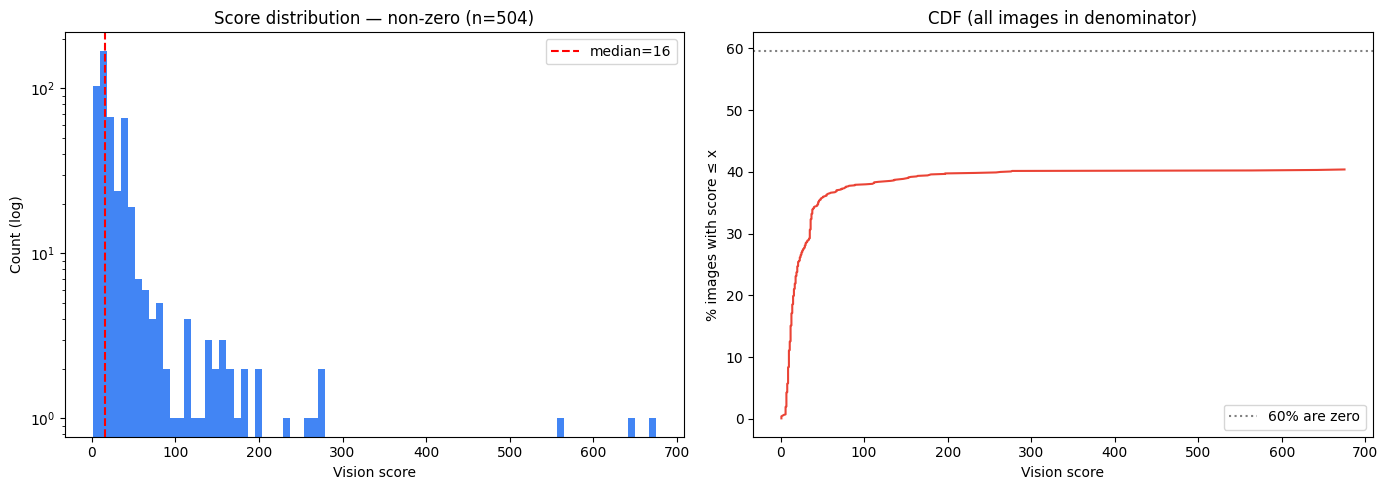

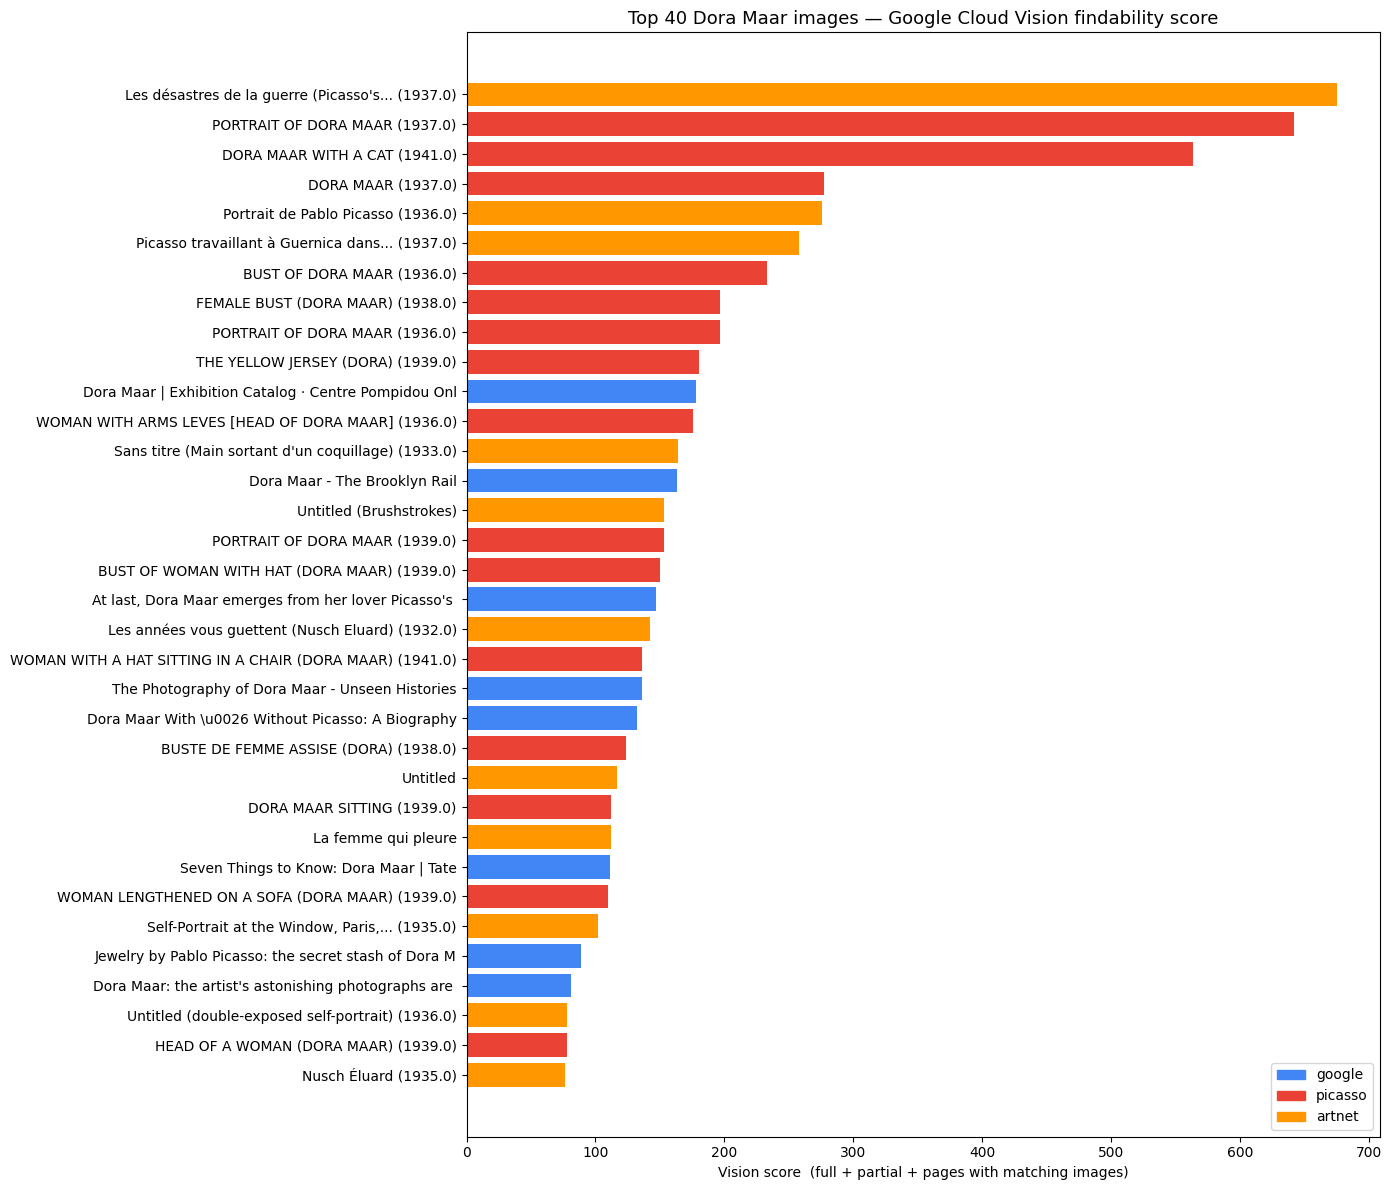

Saved vision_score_distribution.png and vision_histogram.png


In [9]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# ── Load all catalogs ────────────────────────────────────────────────────────
def load_catalog(csv, status_col, skip_dup=False):
    df = pd.read_csv(csv)
    df = df[df[status_col].eq("ok")].copy()
    if skip_dup and "is_dup" in df.columns:
        df = df[~df["is_dup"].eq(True)]
    df["vision_score_num"] = pd.to_numeric(df.get("vision_score"), errors="coerce").fillna(0)
    return df

df_goog = load_catalog("google_search_results.csv", "dl_status", skip_dup=True);  df_goog["catalog"] = "google"
df_pic  = load_catalog("picasso_dora_catalog.csv",  "dl_status");                 df_pic["catalog"]  = "picasso"
df_art  = load_catalog("artnet_catalog.csv",        "status",    skip_dup=True);  df_art["catalog"]  = "artnet"
df_all  = pd.concat([df_goog, df_pic, df_art], ignore_index=True)

scores = df_all["vision_score_num"]
print(f"Total images:  {len(scores)}")
print(f"Zero scores:   {(scores == 0).sum()}  ({(scores==0).mean()*100:.1f}%)")
print(f"Score > 0:     {(scores > 0).sum()}")
print(f"Max score:     {scores.max():.0f}")

# ── 1. Distribution ──────────────────────────────────────────────────────────
COLORS = {"google": "#4285F4", "picasso": "#EA4335", "artnet": "#FF9800"}

nz = scores[scores > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(nz, bins=80, color="#4285F4", edgecolor="none", log=True)
axes[0].axvline(nz.median(), color="red", linestyle="--", label=f"median={nz.median():.0f}")
axes[0].set_xlabel("Vision score"); axes[0].set_ylabel("Count (log)")
axes[0].set_title(f"Score distribution — non-zero (n={len(nz)})"); axes[0].legend()

sorted_nz = np.sort(nz)
cdf = np.arange(1, len(sorted_nz)+1) / len(scores)
axes[1].plot(sorted_nz, cdf * 100, color="#EA4335")
axes[1].axhline((scores==0).mean()*100, color="gray", linestyle=":",
                label=f"{(scores==0).mean()*100:.0f}% are zero")
axes[1].set_xlabel("Vision score"); axes[1].set_ylabel("% images with score ≤ x")
axes[1].set_title("CDF (all images in denominator)"); axes[1].legend()

plt.tight_layout(); plt.savefig("vision_score_distribution.png", dpi=150); plt.show()

# ── 2. Top-40 bar chart ──────────────────────────────────────────────────────
df_top = (df_all[df_all["vision_score_num"] > 0]
          .sort_values("vision_score_num", ascending=False)
          .head(40).reset_index(drop=True))

def make_label(row):
    t = str(row.get("title", "")).strip()
    y = str(row.get("year",  "")).strip()
    base = (t if t and t != "nan" else Path(str(row.get("local_path",""))).stem)[:52]
    return f"{base} ({y})" if y and y != "nan" else base

df_top["label"] = df_top.apply(make_label, axis=1)

fig, ax = plt.subplots(figsize=(14, 12))
ax.barh(df_top["label"], df_top["vision_score_num"],
        color=df_top["catalog"].map(COLORS))
ax.invert_yaxis()
ax.set_xlabel("Vision score  (full + partial + pages with matching images)")
ax.set_title("Top 40 Dora Maar images — Google Cloud Vision findability score", fontsize=13)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(handles=[mpatches.Patch(color=c, label=k) for k, c in COLORS.items()],
          loc="lower right")

plt.tight_layout(); plt.savefig("vision_histogram.png", dpi=150); plt.show()
print(f"Saved vision_score_distribution.png and vision_histogram.png")


Total tiles: 1248  |  non-zero (image): 504  |  zero (white): 744
Reading image dimensions…
  456 image ARs loaded

Rendering vision_collage_A3_portrait.png…
  vision_collage_A3_portrait.png: 886 packed, 362 unpacked (skipped)
    200 tiles rendered…
    400 tiles rendered…
  → saved vision_collage_A3_portrait.png  (3508×4961 px @ 300 dpi,  493 tiles)
vision_collage_A3_portrait.png


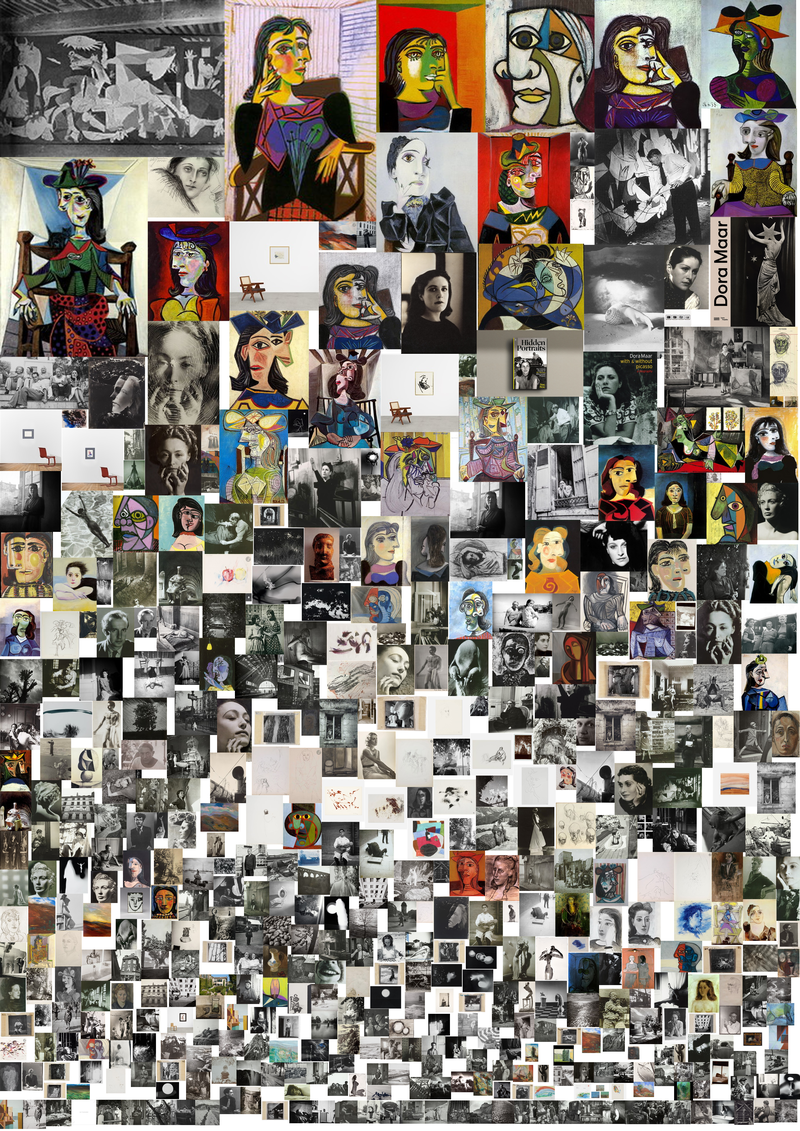

In [12]:
from rectpack import newPacker, MaxRectsBssf
from PIL import Image
import numpy as np
from pathlib import Path

# ── Build tile list sorted by score desc ─────────────────────────────────────
rows = (df_all[["local_path", "vision_score_num", "title"]]
        .sort_values("vision_score_num", ascending=False)
        .reset_index(drop=True))

n_zero    = (rows["vision_score_num"] == 0).sum()
n_nonzero = len(rows) - n_zero
print(f"Total tiles: {len(rows)}  |  non-zero (image): {n_nonzero}  |  zero (white): {n_zero}")

# ── Read each image's actual aspect ratio ────────────────────────────────────
print("Reading image dimensions…")
aspect_ratios = {}
for idx, row in rows.iterrows():
    if row["vision_score_num"] == 0:
        aspect_ratios[idx] = 1.0
        continue
    try:
        with Image.open(str(row["local_path"])) as im:
            w, h = im.size
        aspect_ratios[idx] = w / h if h > 0 else 1.0
    except Exception:
        aspect_ratios[idx] = 1.0
print(f"  {sum(1 for v in aspect_ratios.values() if v != 1.0)} image ARs loaded")

# ── Compute tile (w, h) so area ∝ score and tile matches image AR ────────────
def compute_tiles(canvas_w, canvas_h):
    total_units = sum(max(float(s), 1) for s in rows["vision_score_num"])
    scale = (canvas_w * canvas_h) / total_units
    tiles = []
    for idx, row in rows.iterrows():
        ar   = aspect_ratios[idx]
        s    = float(row["vision_score_num"])
        area = max(s, 1) * scale
        tw   = max(int(np.sqrt(area * ar)), 1)
        th   = max(int(np.sqrt(area / ar)), 1)
        tiles.append((idx, tw, th))
    return tiles

# ── MaxRects packing + rendering ─────────────────────────────────────────────
def render_collage_maxrects(canvas_w, canvas_h, out_path, save_dpi=72):
    tiles = compute_tiles(canvas_w, canvas_h)

    packer = newPacker(pack_algo=MaxRectsBssf, rotation=False)
    packer.add_bin(canvas_w, canvas_h)
    for idx, tw, th in tiles:
        packer.add_rect(tw, th, rid=idx)
    packer.pack()

    packed = {rect.rid: rect for rect in packer[0]}
    n_unpacked = len(tiles) - len(packed)
    if n_unpacked:
        print(f"  {out_path}: {len(packed)} packed, {n_unpacked} unpacked (skipped)")

    canvas = Image.new("RGB", (canvas_w, canvas_h), "white")
    n_rendered = 0

    for idx, row in rows.iterrows():
        rect = packed.get(idx)
        if rect is None:
            continue
        if row["vision_score_num"] == 0:
            continue

        try:
            img = Image.open(str(row["local_path"])).convert("RGB")
            img = img.resize((rect.width, rect.height), Image.LANCZOS)
            canvas.paste(img, (rect.x, rect.y))
            n_rendered += 1
        except Exception:
            pass

        if n_rendered % 200 == 0 and n_rendered > 0:
            print(f"    {n_rendered} tiles rendered…")

    canvas.save(out_path, dpi=(save_dpi, save_dpi))
    print(f"  → saved {out_path}  ({canvas_w}×{canvas_h} px @ {save_dpi} dpi,  {n_rendered} tiles)")
    return canvas

# ── Canvas versions ───────────────────────────────────────────────────────────
# Screen versions
VERSIONS = [
    #(5000, 5000,  "vision_collage_square.png",       72),
    #(5120, 2880,  "vision_collage_16x9.png",         72),
    #(2880, 5120,  "vision_collage_9x16.png",         72),
    # Print @ 300 DPI — pixel dims = mm/25.4 * 300
    # (2480, 3508,  "vision_collage_A4_portrait.png",  300),   # A4  210×297 mm
    # (3508, 2480,  "vision_collage_A4_landscape.png", 300),   # A4  297×210 mm
    # (4961, 3508,  "vision_collage_A3_landscape.png", 300),   # A3  420×297 mm
    (3508, 4961,  "vision_collage_A3_portrait.png",  300),   # A3  297×420 mm
    ]

canvases = {}
for cw, ch, path, dpi in VERSIONS:
    print(f"\nRendering {path}…")
    canvases[path] = render_collage_maxrects(cw, ch, path, save_dpi=dpi)

# ── Preview all versions inline ───────────────────────────────────────────────
from IPython.display import display
for path, canvas in canvases.items():
    print(path)
    display(canvas.resize((800, int(800 * canvas.height / canvas.width)), Image.LANCZOS))
